#Librerías

In [596]:
!pip install category_encoders

In [597]:
# ==========================================
# 1. Librerías Estándar y Utilidades
# ==========================================
import io
import hashlib
import itertools
import requests

# ==========================================
# 2. Manipulación de Datos y Matemáticas
# ==========================================
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, randint, loguniform, uniform

# ==========================================
# 3. Visualización
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 4. Preprocesamiento, Encoders y Pipelines
# ==========================================
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    FunctionTransformer,
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OrdinalEncoder,
    OneHotEncoder,
    TargetEncoder, # TargetEncoder nativo de Scikit-Learn
    label_binarize
)
# Alias para evitar conflicto de nombres con el TargetEncoder de sklearn
from category_encoders import CountEncoder, TargetEncoder as CE_TargetEncoder

# ==========================================
# 5. Modelos de Machine Learning
# ==========================================
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# ==========================================
# 6. Selección de Modelos e Inspección
# ==========================================
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.inspection import permutation_importance

# ==========================================
# 7. Métricas de Evaluación
# ==========================================
from sklearn.metrics import (
    # Métricas de Clasificación
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,

    # Métricas de Regresión
    mean_squared_error,
    mean_absolute_error,
    r2_score,

    # Métricas de Clustering
    silhouette_score
)

#Carga del dataset

In [668]:
url = "https://raw.githubusercontent.com/Mapabaoy12/EncargoMachineLearning2/refs/heads/main/dataML/Spotify_Tracks_Dataset.csv"
HASH_ORIGINAL = "b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd"

In [669]:
try:
    # intento de descarga y validación
    response = requests.get(url)
    response.raise_for_status()  # verifica que url funcione y no de error

    contenido_raw = response.content
    hash_calculado = hashlib.sha256(contenido_raw).hexdigest()

    if hash_calculado == HASH_ORIGINAL:
        print("AUDITORÍA EXITOSA: Integridad de procedencia garantizada.")
        df = pd.read_csv(io.BytesIO(contenido_raw))
        print("Dataset cargado correctamente.")
    else:
        # si hash no coincide, da un error manual
        raise ValueError("El hash no coincide. El archivo ha sido modificado o está corrupto.")

except Exception as e:
    # captura cualquier error y detiene el proceso
    raise RuntimeError(f"FALLO CRÍTICO: No se pudo procesar el dataset. Detalle: {e}")

AUDITORÍA EXITOSA: Integridad de procedencia garantizada.
Dataset cargado correctamente.


In [600]:
# En todo este proyecto se trabajará con random_state = 42
random_state=42

In [601]:
# Depuración de registros nulos y filas redundantes
df_clean = df.dropna(subset=['track_id', 'artists', 'track_name', 'popularity']).copy()
df_clean.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

# Resolución de duplicados a nivel de track único
df_clean = df_clean.groupby('track_id', as_index=False).first()

# Conversión temporal e ingeniería de características vectorizada
df_clean["duration_s"] = df_clean["duration_ms"] / 1000.0
df_clean['valence_instrumentalness_sum'] = df_clean['valence'] + df_clean['instrumentalness']
df_clean['artista_principal'] = df_clean['artists'].astype(str).str.split(';').str[0].str.strip()
df_clean['es_colaboracion'] = df_clean['artists'].astype(str).str.contains(';').astype(int)

In [602]:
class WinsorizerRobusto(BaseEstimator, TransformerMixin):
    """
    Ajusta los cuantiles de recorte exclusivamente en fit()
    y los aplica de forma determinista en transform().
    """
    def __init__(self, limits=(0.05, 0.05)):
        self.limits = limits

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.lower_bounds_ = X_df.quantile(self.limits[0]).to_numpy()
        self.upper_bounds_ = X_df.quantile(1.0 - self.limits[1]).to_numpy()
        self.n_features_in_ = X_df.shape[1]
        return self

    def transform(self, X):
        X_array = np.asarray(X, dtype=np.float64)
        return np.clip(X_array, self.lower_bounds_, self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        return input_features

In [603]:
def evaluar_modelo_clasificacion(modelo: BaseEstimator, X_train: np.array, X_test: np.array, y_train: np.array, y_test: np.array):
  """
  Retorna las métricas del modelo

  Parámetros
  ----------
  modelo : BaseEstimator
    Modelo a evaluar.
  X_train : np.array
    Conjunto de datos de entrenamiento.
  X_test : np.array
    Conjunto de datos de prueba.
  y_train : np.array
    Etiquetas de entrenamiento.
  y_test : np.array
    Etiquetas de prueba
  Returns
  -------
  dict
    Diccionario con las métricas del modelo.

  """
  #modelo.fit(X_train, y_train)

  y_pred = modelo.predict(X_test)
  y_prob = modelo.predict_proba(X_test)

  return {
    "accuracy": accuracy_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred, average='weighted'),
    "precision": precision_score(y_test, y_pred, zero_division=0, average='weighted'),
    "recall": recall_score(y_test, y_pred, average='weighted'),
    "roc_auc": roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')
  }

In [604]:
def evaluar_modelo_regresion(modelo: BaseEstimator, X_train: np.array, X_test: np.array, y_train: np.array, y_test: np.array):
  """
  Retorna las métricas del modelo

  Parámetros
  ----------
  modelo : BaseEstimator
    Modelo a evaluar.
  X_train : np.array
    Conjunto de datos de entrenamiento.
  X_test : np.array
    Conjunto de datos de prueba.
  y_train : np.array
    Etiquetas de entrenamiento.
  y_test : np.array
    Etiquetas de prueba
  Returns
  -------
  dict
    Diccionario con las métricas del modelo.

  """
  modelo.fit(X_train, y_train)

  y_pred = modelo.predict(X_test)

  return {
    "mean_absolute_error": mean_absolute_error(y_test, y_pred),
    "r2_score": r2_score(y_test, y_pred)
  }

In [605]:
class CorrelationFilter(BaseEstimator, TransformerMixin):
  """
  Eliminación de variables correlacionadas

  Parámetros
  ----------
  BaseEstimator : Clase base para estimadores en scikit-learn.
  TransformerMixin : Clase base para transformadores en scikit-learn.

  Atributos
  ---------
  columns_to_drop_ : array-like
    Nombres de las columnas a eliminar.
  threshold : float
    Umbral de correlación.
  Returns
  -------
  DataFrame
    Conjunto de datos sin variables correlacionadas.
  """
  def __init__(self, threshold=0.9):
    self.threshold = threshold
    self.columns_to_drop_ = None

  def fit(self, X, y=None):
    X_df = pd.DataFrame(X)

    corr_matrix = X_df.corr().abs()
    upper = corr_matrix.where(
      np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    self.columns_to_drop_ = [
        col for col in upper.columns if any(upper[col] > self.threshold)
    ]

    return self

  def transform(self, X):
    X_df = pd.DataFrame(X)
    X_filtered = X_df.drop(columns=self.columns_to_drop_, errors="ignore")
    return X_filtered.values

In [606]:
class DataFrameConverter(BaseEstimator, TransformerMixin):
  """
  Convierte un array en un DataFrame

  Parámetros
  ----------
  BaseEstimator : Clase base para estimadores en scikit-learn.
  TransformerMixin : Clase base para transformadores en scikit-learn.

  Atributos
  ---------
  feature_names_ : array-like
    Nombres de las columnas.
  Returns
  -------
  DataFrame
    Conjunto de datos con nombres de columnas.
  """
  def __init__(self, preprocessor):
    self.preprocessor = preprocessor
    self.feature_names_ = None

  def fit(self, X, y=None):
    # Obtener nombres después de fit del preprocessor
    self.feature_names_ = self.preprocessor.get_feature_names_out()
    return self

  def transform(self, X):
    return pd.DataFrame(X, columns=self.feature_names_)

#Análisis exploratorio de los datos

El listado de variables que forman parte del dataset es el siguiente:

"track_id": Identificador de Spotify para la canción

"artists": Artista de la canción, si hay más de uno se separa con ;

"album_name": Álbum donde la canción aparece

"track_name": Nombre de la pista de audio musical

"popularity": Popularidad de la canción bajo una puntuación de 0 a 100

"duration_ms": Duración en segundos

"explicit": Contenido explícito de la canción (letras), variable False o True

"danceability": Escala que denomina qué tan bailable es una canción de 0.0 a 1.0

"energy": Intensidad de la canción medida en 0.0 a 1.0

"key": Tonalidad / escala de notas de la canción, del 0 al 11

"loudness": Sonoridad de la canción medida en decibeles

"mode": Escala melódica de la canción

"speechiness": Cantidad de palabras en escala de 0.0 a 1.0

"acousticness": Escala de 0.0 a 1.0 para medir si una canción es acústica

"instrumentalness": Escala de 0.0 a 1.0 para medir si una canción es más instrumental

"liveness": Escala de 0.0 a 1.0 para medir si la canción fue cantada en live

"valence": Positividad medida en 0.0 a 1.0

"tempo": Tempo estimado de la canción

"time_signature": Cantidad de beats en una canción

"track_genre": Género de la canción

In [670]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [608]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [609]:
#fila(s) con valores nulos
filas_con_nulos = df[df.isna().any(axis=1)]
filas_con_nulos

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


No se puede hacer nada con este track sin nombre, artista, popularidad, etc etc. Lo mejor es borrarlo y se tendrá 13999/13999 registros sin nulos.

In [610]:
# eliminar track_id 1kR4gIb7nGxHPI3D2ifs59 del df ya que es el único nulo
df.drop(df[df['track_id'] == '1kR4gIb7nGxHPI3D2ifs59'].index, inplace=True)

In [611]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 113999 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        113999 non-null  int64  
 1   track_id          113999 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        113999 non-null  int64  
 6   duration_ms       113999 non-null  int64  
 7   explicit          113999 non-null  bool   
 8   danceability      113999 non-null  float64
 9   energy            113999 non-null  float64
 10  key               113999 non-null  int64  
 11  loudness          113999 non-null  float64
 12  mode              113999 non-null  int64  
 13  speechiness       113999 non-null  float64
 14  acousticness      113999 non-null  float64
 15  instrumentalness  113999 non-null  float64
 16  liveness          113999 

In [612]:
# Se descarta la columna "Unnamed: 0" del dataset por la nula relevancia predictiva
df.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

In [613]:
# Conversión de milisegundos a segundos y renombramiento

df["duration_ms"] = df["duration_ms"] / 1000
df.rename(columns={"duration_ms": "duration_s"}, inplace=True)

In [614]:
# Cantidad total de géneros únicos (excluyendo nulos por defecto)
total_generos = df['track_genre'].nunique()
print(f"Total de géneros únicos: {total_generos}")

Total de géneros únicos: 114


In [615]:
# buscar duplicado considerando track_id y track_genre
duplicados_id = df[df.duplicated(subset=['track_id', 'track_genre'], keep=False)].sort_values(by='track_id')
duplicados_id.shape

(894, 20)

In [616]:
#Eliminación de duplicados que tengan el "track_id" y "track_genre" igual
df.drop_duplicates(subset=['track_id', 'track_genre'], inplace=True)


In [617]:
# correlación de variables numéricas con respecto a "popularity"
df.select_dtypes(include=['number']).corrwith(df['popularity'],method='spearman').sort_values(ascending=False)

,0
popularity,1.000000
time_signature,0.035834
loudness,0.033146
duration_s,0.026528
danceability,0.025760
tempo,0.015990
acousticness,0.011263
key,-0.002860
liveness,-0.008356
mode,-0.015554


In [618]:
#Agrupamos el dataset por identificador unico, aplicando .first()
#para conservar unicamente la primera aparicion
df = df.groupby('track_id', as_index=False).first()

In [619]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89740 entries, 0 to 89739
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          89740 non-null  object 
 1   artists           89740 non-null  object 
 2   album_name        89740 non-null  object 
 3   track_name        89740 non-null  object 
 4   popularity        89740 non-null  int64  
 5   duration_s        89740 non-null  float64
 6   explicit          89740 non-null  bool   
 7   danceability      89740 non-null  float64
 8   energy            89740 non-null  float64
 9   key               89740 non-null  int64  
 10  loudness          89740 non-null  float64
 11  mode              89740 non-null  int64  
 12  speechiness       89740 non-null  float64
 13  acousticness      89740 non-null  float64
 14  instrumentalness  89740 non-null  float64
 15  liveness          89740 non-null  float64
 16  valence           89740 non-null  float6

#Feature engineering

In [620]:
#La columna 'artist' agrupa multiples interpretes en una sola cadena de texto lo que
#provoca una alta cardinalidad y no concede el valor real de los artistas.
#Para evitar esto se crean dos variables 'artista_principal' y 'es_colaboracion'

#Aisla al primer interprete de las canciones garantizando tener una muestra estadistica solida
df['artista_principal'] = df['artists'].astype(str).str.split(';').str[0].str.strip()
#Rescata la presencia de artistas secuandarios para medir el impulso que genera la union de diferentes artistas
df['es_colaboracion'] = df['artists'].astype(str).str.contains(';').astype(int)


In [621]:
# variables cuantitativas y cualitativas
variables_cuantitativas = ["popularity", "duration_s", "danceability", "energy", "key", "loudness", "mode", "speechiness", "acousticness",  "instrumentalness", "liveness", "tempo", "time_signature"]
variables_cualitativas = [ "artists", "album_name", "track_name", "track_genre", "artista_principal", "es_colaboracion"]


In [622]:
# Analizar correlación de variables categóricas con popularity, para eso se pasa popularity a categórica
# 1. Categorizar la popularidad (ej. por umbral de negocio)
df['popularity_cat'] = pd.qcut(df['popularity'], q=5)

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

# 2. Calcular solo sobre variables de cardinalidad manejable (como track_genre)
#v_cramer = cramers_v(df['track_genre'], df['popularity_cat'])
#print(f"V de Cramér (track_genre vs popularity_cat): {v_genre:.4f}")

for col in variables_cualitativas:
    v_cramer = cramers_v(df[col], df['popularity_cat'])
    print(f"V de Cramér ({col} vs popularity_cat): {v_cramer:.4f}")


V de Cramér (artists vs popularity_cat): 0.8423
V de Cramér (album_name vs popularity_cat): 0.9180
V de Cramér (track_name vs popularity_cat): 0.9417
V de Cramér (track_genre vs popularity_cat): 0.5703
V de Cramér (artista_principal vs popularity_cat): 0.7902
V de Cramér (es_colaboracion vs popularity_cat): 0.1025


In [623]:
# ver las categorías que generó para popularity categórico
df["popularity_cat"].unique()

[(40.0, 52.0], (15.0, 26.0], (52.0, 100.0], (-0.001, 15.0], (26.0, 40.0]]
Categories (5, interval[float64, right]): [(-0.001, 15.0] < (15.0, 26.0] < (26.0, 40.0] <
                                           (40.0, 52.0] < (52.0, 100.0]]

In [624]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89740 entries, 0 to 89739
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   track_id           89740 non-null  object  
 1   artists            89740 non-null  object  
 2   album_name         89740 non-null  object  
 3   track_name         89740 non-null  object  
 4   popularity         89740 non-null  int64   
 5   duration_s         89740 non-null  float64 
 6   explicit           89740 non-null  bool    
 7   danceability       89740 non-null  float64 
 8   energy             89740 non-null  float64 
 9   key                89740 non-null  int64   
 10  loudness           89740 non-null  float64 
 11  mode               89740 non-null  int64   
 12  speechiness        89740 non-null  float64 
 13  acousticness       89740 non-null  float64 
 14  instrumentalness   89740 non-null  float64 
 15  liveness           89740 non-null  float64 
 16  vale

# Visualizaciones y hallazgos

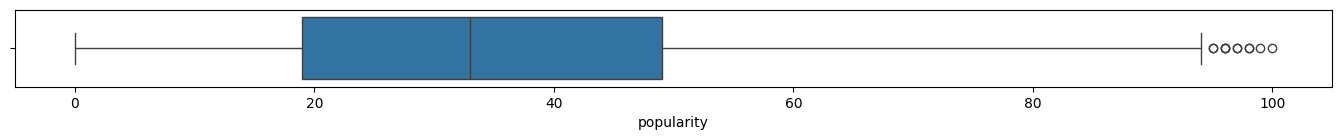

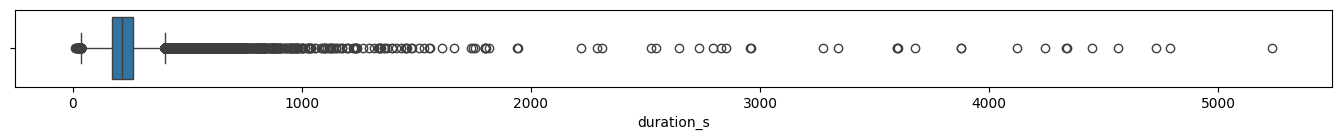

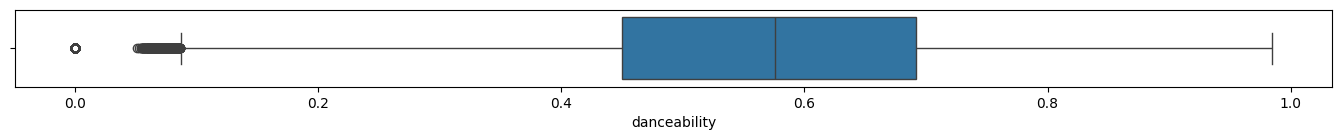

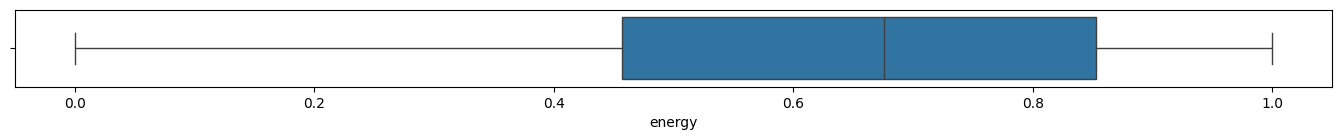

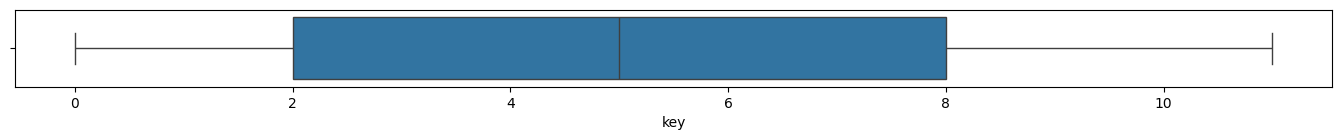

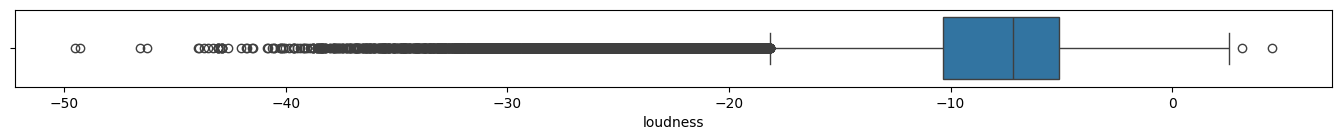

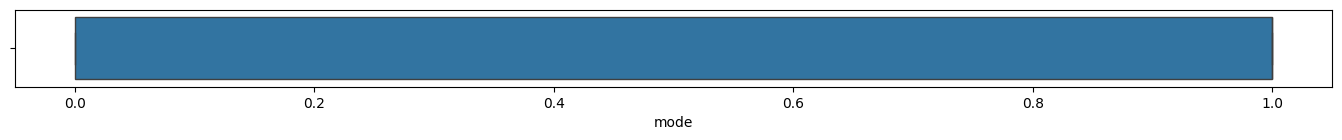

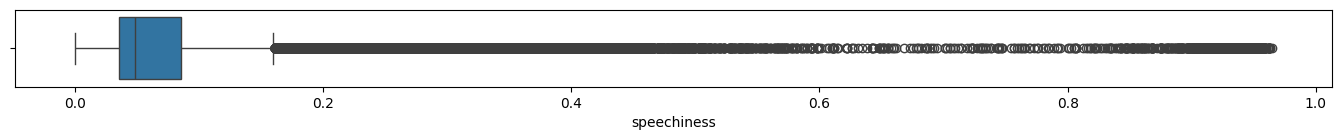

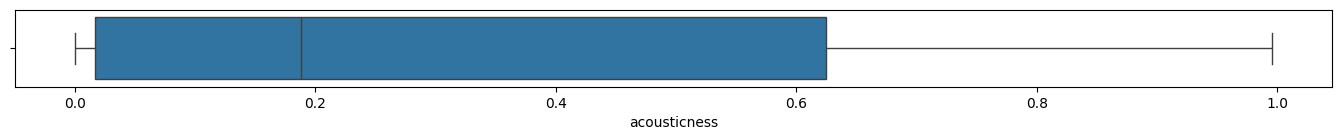

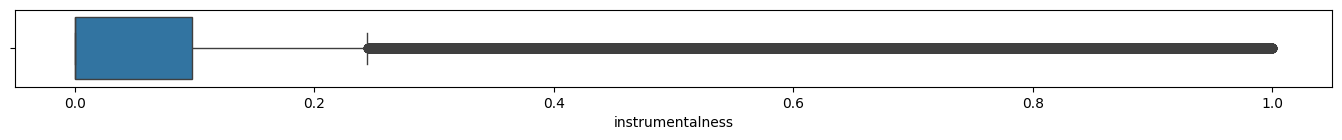

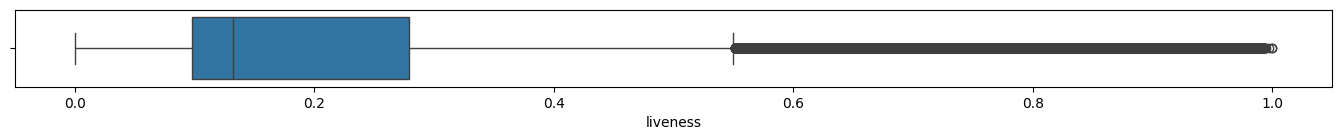

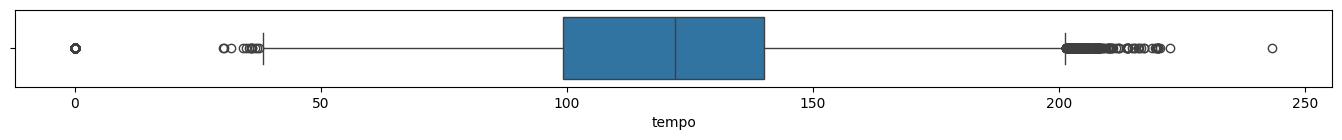

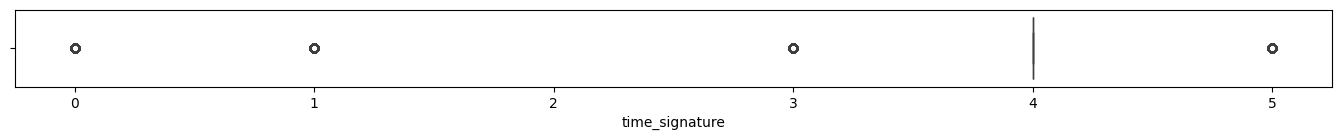

In [625]:
#Comprobación de outliers
for col in variables_cuantitativas:
    plt.figure(figsize = (17,1))
    sns.boxplot(data=df[variables_cuantitativas], x = col)
    #Este ciclo for nos permite visualisar las columnas numéricas con su visualización bajo boxplot para ver la presencia de outliers dentro de nuestros datos



El gráfico de bloxplot nos permite ver la cantidad de valores outliers y distribuciones de cada variable, cada uno con su respectiva escala.
Cajas como danceability y energy se encuentran inclinados hacia la derecha, debido a que la mayoría de canciones están hechas para ser dinámicas y rítmicas.

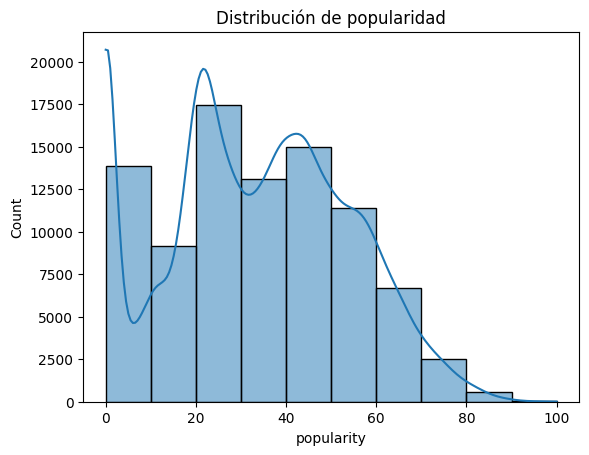

In [626]:
# Gráfico de histograma con líneas para distribución de popularidad
sns.histplot(data=df, x="popularity", bins=10, kde=True)
plt.title("Distribución de popularidad")
plt.show()

Se presencia una distribución hacia la izquierda con una acumulación masiva de canciones con popularidad 0, dándonos a entender que en la totalidad de las canciones la mayoría presenta un rango de popularidad de [0-50], mientras que hay un número reducido de canciones con un umbral de popularidad del [51-100], desde ahí va en declive.
El gráfico al no comportarse como una campana de Gauss perfecta, teniendo en sí, múltiples jorobas, dejando en criterio que las canciones no se comportan de forma normal o predecible.

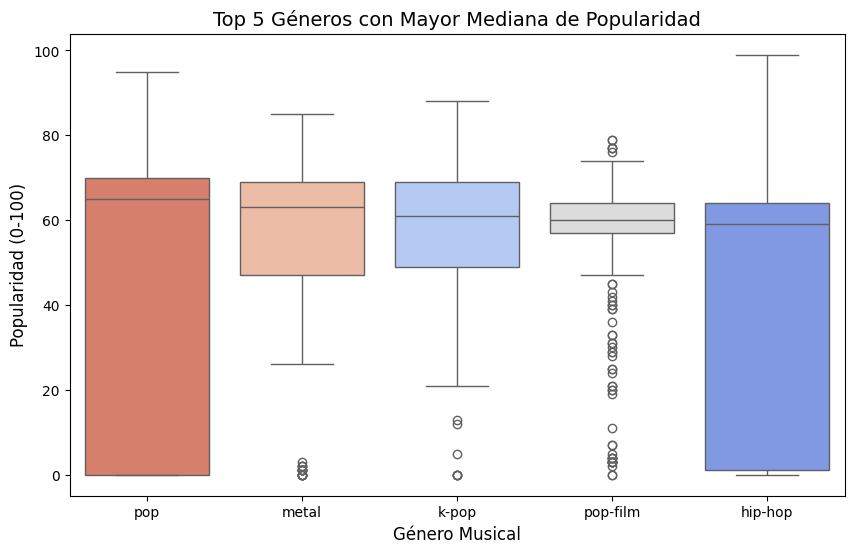

In [627]:
# 1. Identificar los 5 géneros con la mayor mediana de popularidad
top_5_generos = df.groupby('track_genre')['popularity'].median().nlargest(5).index

# 2. Filtrar el dataset para conservar solo las filas de esos 5 géneros
df_top5 = df[df['track_genre'].isin(top_5_generos)]

# 3. Generar el gráfico corregido
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_top5,
    x='track_genre',
    y='popularity',
    hue='track_genre',     # Asigna la variable categórica a hue
    order=top_5_generos,
    palette='coolwarm',
    legend=False           # Oculta la leyenda redundante
)

# 4. Ajustes estéticos para la presentación
plt.title('Top 5 Géneros con Mayor Mediana de Popularidad', fontsize=14)
plt.xlabel('Género Musical', fontsize=12)
plt.ylabel('Popularidad (0-100)', fontsize=12)
plt.show()

Géneros como el pop y hip-hop presentan rangos intercuartiles más largos a comparación de los otros, estos abarcan desde el éxito total hasta el fracaso absoluto, significando que invertir en estos conlleva una apuesta de alto riesgo ya que no garantizan popularidad.
El k-pop y pop-film presentan cajas compactas teniendo una mediana alta y dispersión baja dando segurar como mercado seguro y estable.
A pesar de la estabilidad de pop-film, chill o k-pop se hace presencia de gran cantidad de outliers cercanos a una popularidad baja, concientizando que el género no basta por si solo para medir la popularidad y se necesitan de otras variables.

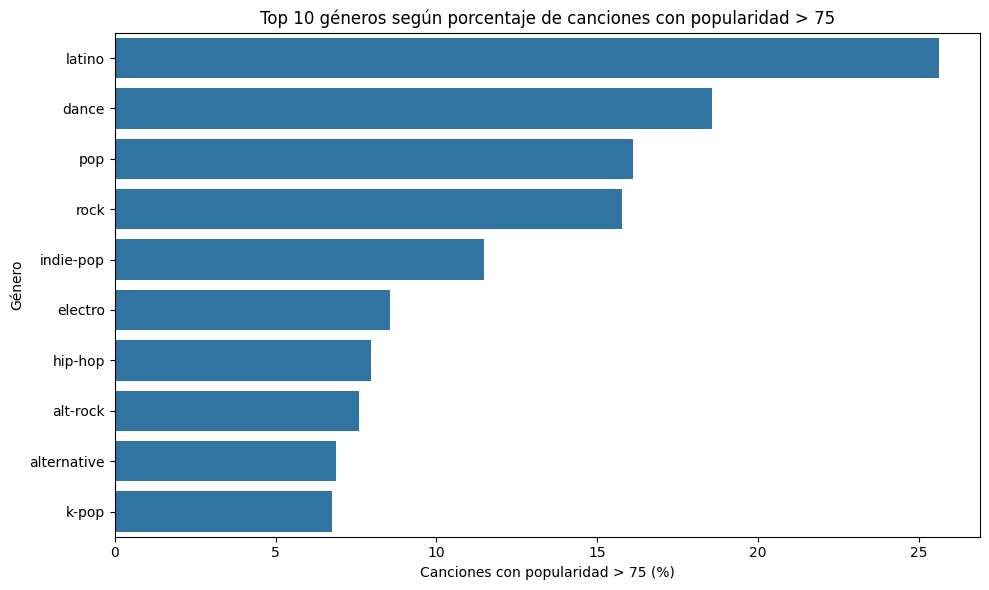

In [628]:
#Variable para aislar canciones que superen el umbral de 75 de popularidad
df['hit_popular'] = df['popularity'] > 75 #Variable auxiliar
#Agregación y filtrado estadístico
hit_rate_genero = (
    df.groupby('track_genre')
      .agg(
          cantidad_canciones=('track_id', 'count'),#Volumen total de género
          porcentaje_hits=('hit_popular', 'mean')#Tasa de conversión a "hit"
      )
      #Se exluyen géneros con menos de 200 canciones
      .query('cantidad_canciones >= 200')
      #Transformamos la proporción (0-1) a porcentaje (0-100)
      .assign(porcentaje_hits=lambda x: x['porcentaje_hits'] * 100)
      #Se ordena de mayor a menor
      .sort_values('porcentaje_hits', ascending=False)
      .reset_index()
)
#Variable con el Top 10
top_generos = hit_rate_genero.head(10)
#Configuracion visual
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_generos,
    x='porcentaje_hits',
    y='track_genre'
)

plt.title('Top 10 géneros según porcentaje de canciones con popularidad > 75')
plt.xlabel('Canciones con popularidad > 75 (%)')
plt.ylabel('Género')

plt.tight_layout()
plt.show()

Se observa una mayor proporción de canciones pop y dance como exitosas, lo que puede indicar una predilección del público a música más orientada al baile más que a la complejidad musical.


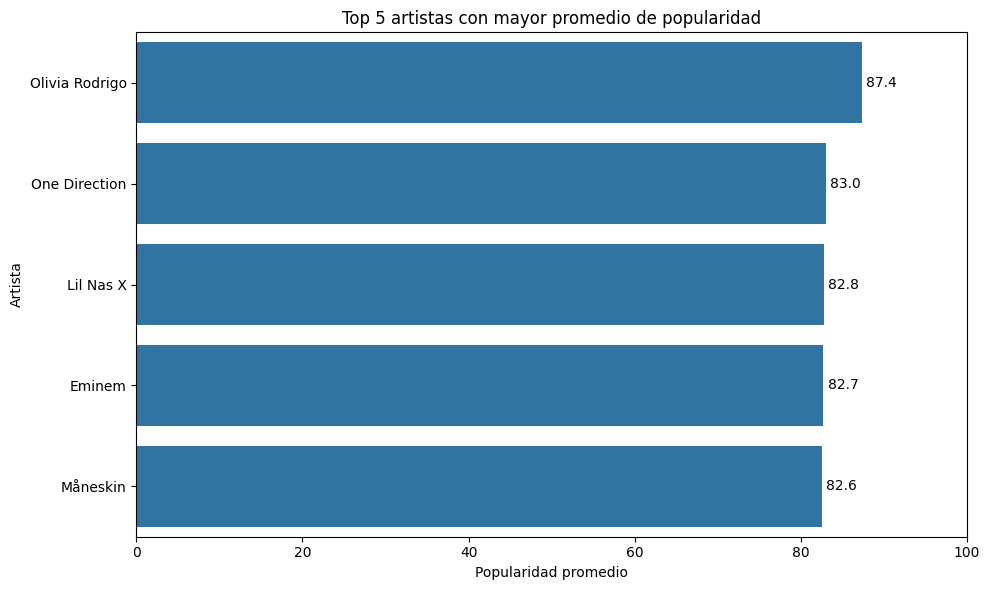

In [629]:
#Gráfico de barras para los 5 artistas con mayor popularidad promedio
# Calcular cantidad de canciones y popularidad promedio por artista
artistas = (
    df.groupby('artista_principal')
      .agg(
          promedio_popularidad=('popularity', 'mean'),
          cantidad_canciones=('track_id', 'count')
      )
      .query('cantidad_canciones >= 5')
      .sort_values('promedio_popularidad', ascending=False)
      .head(5)
      .reset_index()
)
# Visualización
plt.figure(figsize=(10, 6))
sns.barplot(
    data=artistas,
    x='promedio_popularidad',
    y='artista_principal'
)
plt.title('Top 5 artistas con mayor promedio de popularidad')
plt.xlabel('Popularidad promedio')
plt.ylabel('Artista')
plt.xlim(0, 100)
# Mostrar valor sobre cada barra
for i, valor in enumerate(artistas['promedio_popularidad']):
    plt.text(
        valor + 0.5,
        i,
        f'{valor:.1f}',
        va='center'
    )
plt.tight_layout()
plt.show()

En el top 5, se encuentra Olivia Rodrigo liderando con 87.4 como la artista con mayor promedio de popularidad, siguiendo The Kid LAROI con 85.2 y Chris Brown con 84.0, demostrando cifras competitivas en una escala del 0 al 100.
Esto asegura que el artista contiene un peso considerable en las reproducciones, independiente de otras variables.
Considerando la poca escala de éxito dentro del dataset, los artistas mencionados representan los outliers de éxito extremo.


#Preprocesamiento

### Justificación de Selección y Descarte de Variables

La selección final de características responde a los hallazgos estadísticos del Análisis Exploratorio de Datos (EDA) y a la necesidad de entregar predictores con señal real, evitando introducir ruido o sobreajuste (*overfitting*) en el modelo.

---

### 1. Variables Seleccionadas para el Modelo

* **`artista_principal` (Target Encoding):**
  * Presenta la asociación categórica más determinante del catálogo ($V$ de Cramér $\approx 0.7834$).
  * El reconocimiento comercial y la base de oyentes del músico constituyen el factor individual de mayor poder explicativo del éxito. Se codifica mediante *Target Encoding* continuo regularizado para capturar su impacto reduciendo la dimensionalidad a una sola columna sin inducir sobreajuste.

* **`track_genre` (Target Encoding):**
  * Registra una fuerte asociación estadística frente a la popularidad ($V$ de Cramér $\approx 0.5433$).
  * El género define las pautas de consumo, posicionamiento en playlists y visibilidad en la plataforma. Tras consolidar los 26 géneros infrecuentes bajo la categoría `'otros'` (dejando 88 grupos representativos), se procesa con *Target Encoding* para entregar al modelo una señal continua y directa del impacto del estilo musical sin dispersar los árboles en 88 columnas binarias.

* **`es_colaboracion` (Numérica / Binaria):**
  * Muestra una asociación moderada con el target ($V$ de Cramér $\approx 0.1180$).
  * Modela la tracción comercial adicional generada por lanzamientos conjuntos (*feats*), los cuales expanden la audiencia compartida y favorecen el alcance algorítmico.

* **Variables acústicas continuas con correlación relevante ($\vert{}r\vert{} \ge 0.03$):**
  * **`instrumentalness` ($r \approx -0.0783$):** Es el atributo de audio con la mayor correlación negativa frente a la popularidad. La marcada penalización lineal de temas instrumentales refleja la preferencia masiva del público por producciones con presencia vocal.
  * **`speechiness` ($r \approx -0.0681$):** Registra una asociación inversa relevante, permitiendo al algoritmo diferenciar entre canciones melódicas convencionales y formatos con alta densidad de palabras o contenido hablado.
  * **`valence` ($r \approx -0.0425$):** Refleja la positividad o estado anímico musical. Mantiene una magnitud de correlación superior al 4%, capturando matices emocionales vinculados a las preferencias de los usuarios.
  * **`time_signature` ($r \approx +0.0358$):** Métrica rítmica asociada a la cadencia y métrica de compás. Aunque su variabilidad es acotada, supera el umbral del 3% y aporta regularidad estructural a las pistas.
  * **`loudness` ($r \approx +0.0331$):** Indicador de potencia sonora en decibeles. Pistas con mayor sonoridad y masterización comercial presentan una ligera correlación positiva con el target.


---

### 2. Justificación de Variables Descartadas

* **Identificadores y textos de alta cardinalidad (`track_id`, `track_name`, `album_name`, `artists` original):**
  * Si bien registran valores de $V$ de Cramér elevados (entre 0.83 y 0.94), esto corresponde a un artefacto matemático debido a que prácticamente cada fila posee un identificador único.
  * Su inclusión provocaría memorización espuria (*data leakage* / sobreajuste severo), impidiendo que el modelo generalice frente a nuevas canciones.

* **Variables acústicas numéricas con correlación marginal ($\vert{}r\vert{} < 0.03$):**
  * Se descartaron `energy` ($r \approx -0.0267$), `danceability` ($r \approx +0.0258$), `duration_s` ($r \approx +0.0265$), `tempo` ($r \approx +0.0160$), `mode` ($r \approx -0.0156$), `acousticness` ($r \approx +0.0113$), `liveness` ($r \approx -0.0084$) y `key` ($r \approx -0.0029$).
  * Al situarse por debajo del umbral del 3% de correlación lineal absoluta, su capacidad explicativa individual es prácticamente nula (explican menos del 0.07% de la varianza del objetivo), por lo que conservarlas solo introduciría dimensionalidad superflua y ruido muestral en los estimadores.

In [630]:
#Enrutamiento de Características
cols_num = ['speechiness', 'time_signature', 'valence', 'loudness', 'instrumentalness']
cols_bin = ['es_colaboracion']
cols_nom_te = ['artista_principal', 'track_genre']

In [631]:
pipe_num = Pipeline(
    steps=[
        ("winsorizer", WinsorizerRobusto(limits=(0.02, 0.02))),
        ("imputacion", SimpleImputer(strategy="mean")), #Se utiliza la media ya que Winsorizer cortará los extremos
        ("escalado", StandardScaler())
    ]
)


# Pipeline Cualitativo TargetEncoder para Clasificación
pipe_te_cl = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("encoder", TargetEncoder(target_type="auto", smooth="auto",
        cv = 5, random_state = 42))
    ]
)



# Pipeline Cualitativo TargetEncoder para Regresión
pipe_te_re = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("encoder", TargetEncoder(target_type="continuous", smooth="auto",
        cv = 5, random_state = 42))
    ]
)


# Preprocesador para Clasificación
preprocesadorCL = ColumnTransformer(
    transformers=[
        ("num", pipe_num, cols_num),
        ("bin", 'passthrough', cols_bin),
        ("nom_te", pipe_te_cl, cols_nom_te)
    ],
    remainder='passthrough', # Deja intactas las columnas que no listamos (como las binarias)
    verbose_feature_names_out=False
).set_output(transform="pandas")

# Preprocesador para Regresión
preprocesadorRE = ColumnTransformer(
    transformers=[
        ("num", pipe_num, cols_num),
        ("bin", 'passthrough', cols_bin),
        ("nom_te", pipe_te_re, cols_nom_te)
    ],
    remainder='passthrough', # Deja intactas las columnas que no listamos (como las binarias)
    verbose_feature_names_out=False
).set_output(transform="pandas")

In [632]:
pipeline_clasificacion = Pipeline(steps=[
    ("duplicados", FunctionTransformer()),
    ("preprocesador", preprocesadorCL),
    ("colinealidad", CorrelationFilter(threshold=0.9))

])

pipeline_regresion = Pipeline(steps=[
    ("duplicados", FunctionTransformer()),
    ("preprocesador", preprocesadorRE),
    ("colinealidad", CorrelationFilter(threshold=0.9))

])

# Modelos de clasificación

##Clasificacion (DecisionTreeClassifier)

In [633]:
#Variable objetivo 'popularity'
X = df[['speechiness', 'time_signature', 'valence', 'loudness', 'instrumentalness', 'es_colaboracion', 'track_genre', 'artista_principal']]
# Agrupar la popularidad en 3 categorías equilibradas
y_categorica = pd.qcut(df['popularity'], q=5, labels=["Muy Baja",'Baja', 'Media', 'Alta', "Muy Alta"])

# Ahora sí puedes hacer el split usando stratify
X_train, X_test, y_train, y_test = train_test_split(X, y_categorica, test_size=0.2, random_state=42, stratify=y_categorica)

In [634]:
# pipeline para modelo de regresión lineal base
pipeline_modelo_dtc = Pipeline(steps=[
    ("preprocesamiento", pipeline_clasificacion),
    ("modelo", DecisionTreeClassifier())
])


In [635]:
pipeline_modelo_dtc.fit(X_train, y_train)

Pipeline(steps=[('preprocesamiento',
                 Pipeline(steps=[('duplicados', FunctionTransformer()),
                                 ('preprocesador',
                                  ColumnTransformer(remainder='passthrough',
                                                    transformers=[('num',
                                                                   Pipeline(steps=[('winsorizer',
                                                                                    WinsorizerRobusto(limits=(0.02,
                                                                                                              0.02))),
                                                                                   ('imputacion',
                                                                                    SimpleImputer()),
                                                                                   ('escalado',
                                                                                    StandardScaler())]),
                                                                   ['speechiness',
                                                                    'time_signature',
                                                                    'valence',
                                                                    'loudness',
                                                                    'instrumentalness']),
                                                                  ('bin',
                                                                   'passthrough',
                                                                   ['es_colaboracion']),
                                                                  ('nom_te',
                                                                   Pipeline(steps=[('imputacion',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('encoder',
                                                                                    TargetEncoder(random_state=42))]),
                                                                   ['artista_principal',
                                                                    'track_genre'])],
                                                    verbose_feature_names_out=False)),
                                 ('colinealidad', CorrelationFilter())])),
                ('modelo', DecisionTreeClassifier())])

In [636]:
# Evaluación
metricas_dtc = evaluar_modelo_clasificacion(pipeline_modelo_dtc, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_dtc['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_dtc['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_dtc['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_dtc['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_dtc['recall']:.4f}")

Accuracy            : 0.6092
F1 Score:           : 0.6092
ROC AUC Score       : 0.7566
Precision           : 0.6093
Recall              : 0.6092


In [637]:
result = permutation_importance(
    pipeline_modelo_dtc,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

In [638]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_modelo_dtc.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_modelo_dtc.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.74826
Score del modelo en test                :0.60920


In [639]:
importancias = pd.Series(result.importances_mean, index=X_test.columns)
print(importancias.sort_values(ascending=False))

artista_principal    0.277123
track_genre          0.237787
instrumentalness     0.021105
valence              0.019233
loudness             0.014185
speechiness          0.012168
es_colaboracion      0.003666
time_signature       0.000758
dtype: float64


##DecisionTreeRandomSearchCV

In [640]:
param_grid_dtc = {
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__max_depth': randint(5, 15),
    'modelo__min_samples_split': randint(10, 60),
    'modelo__min_samples_leaf': randint(5, 30),
    'modelo__class_weight': ['balanced', None]
}

In [641]:
random_search = RandomizedSearchCV(
    estimator=pipeline_modelo_dtc,
    param_distributions=param_grid_dtc,
    n_iter=15,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="f1_weighted",
    n_jobs=-1,
    random_state=42,
    error_score='raise'
)

random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   error_score='raise',
                   estimator=Pipeline(steps=[('preprocesamiento',
                                              Pipeline(steps=[('duplicados',
                                                               FunctionTransformer()),
                                                              ('preprocesador',
                                                               ColumnTransformer(remainder='passthrough',
                                                                                 transformers=[('num',
                                                                                                Pipeline(steps=[('winsorizer',
                                                                                                                 WinsorizerRobusto(limits=(0.02,
                                                                                                                                           0.02))),
                                                                                                                ('i...
                                                              'entropy'],
                                        'modelo__max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d2d4882d5b0>,
                                        'modelo__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d2d4601e210>,
                                        'modelo__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d2d4882d810>},
                   random_state=42, scoring='f1_weighted')

In [642]:
best_params_tree = random_search.best_params_
print(f"Mejores parametros para DecisionTree: {best_params_tree}")

Mejores parametros para DecisionTree: {'modelo__class_weight': 'balanced', 'modelo__criterion': 'gini', 'modelo__max_depth': 11, 'modelo__min_samples_leaf': 25, 'modelo__min_samples_split': 18}


In [643]:
# Train the model with the best hyperparameters for Decision Tree
best_tree = random_search.best_estimator_

# Predict on the test set for Decision Tree
y_pred_tree = best_tree.predict(X_test)

In [644]:
metricas_dtc_random = evaluar_modelo_clasificacion(best_tree, X_train, X_test, y_train, y_test)

print(f"{'Accuracy':<20}: {metricas_dtc_random['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_dtc_random['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_dtc_random['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_dtc_random['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_dtc_random['recall']:.4f}")

Accuracy            : 0.6951
F1 Score:           : 0.6937
ROC AUC Score       : 0.9126
Precision           : 0.6943
Recall              : 0.6951


In [645]:
print(f"{'Score del modelo en entrenamiento':<40}:{best_tree.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{best_tree.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.76509
Score del modelo en test                :0.69512


##Clasificacion(RegresionLogistica)

In [646]:
# pipeline para modelo de regresión lineal base
pipeline_modelo_logistic = Pipeline(steps=[
    ("preprocesamiento", pipeline_clasificacion),
    ("modelo", LogisticRegression())
])
pipeline_modelo_logistic.fit(X_train, y_train)


Pipeline(steps=[('preprocesamiento',
                 Pipeline(steps=[('duplicados', FunctionTransformer()),
                                 ('preprocesador',
                                  ColumnTransformer(remainder='passthrough',
                                                    transformers=[('num',
                                                                   Pipeline(steps=[('winsorizer',
                                                                                    WinsorizerRobusto(limits=(0.02,
                                                                                                              0.02))),
                                                                                   ('imputacion',
                                                                                    SimpleImputer()),
                                                                                   ('escalado',
                                                                                    StandardScaler())]),
                                                                   ['speechiness',
                                                                    'time_signature',
                                                                    'valence',
                                                                    'loudness',
                                                                    'instrumentalness']),
                                                                  ('bin',
                                                                   'passthrough',
                                                                   ['es_colaboracion']),
                                                                  ('nom_te',
                                                                   Pipeline(steps=[('imputacion',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('encoder',
                                                                                    TargetEncoder(random_state=42))]),
                                                                   ['artista_principal',
                                                                    'track_genre'])],
                                                    verbose_feature_names_out=False)),
                                 ('colinealidad', CorrelationFilter())])),
                ('modelo', LogisticRegression())])

In [647]:
# Evaluación
metricas_logistic = evaluar_modelo_clasificacion(pipeline_modelo_logistic, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_logistic['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_logistic['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_logistic['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_logistic['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_logistic['recall']:.4f}")

Accuracy            : 0.6922
F1 Score:           : 0.6906
ROC AUC Score       : 0.9136
Precision           : 0.6899
Recall              : 0.6922


In [648]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_modelo_logistic.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_modelo_logistic.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.76273
Score del modelo en test                :0.69217


##Regresion Logistica con RandomSearch

In [649]:


# Se definen las distribuciones de parámetros
param_distributions = [
    # 1. solver 'lbfgs'
    {
        'modelo__solver': ['lbfgs'],
        'modelo__penalty': ['l2'],
        'modelo__C': loguniform(1e-3, 1e3) # Elige cualquier valor entre 0.001 y 1000
    },
    {
        'modelo__solver': ['lbfgs'],
        'modelo__penalty': [None]
    },

    # 2. solver 'liblinear' (l1 o l2)
    {
        'modelo__solver': ['liblinear'],
        'modelo__penalty': ['l1', 'l2'],
        'modelo__C': loguniform(1e-3, 1e3)
    },

    # 3. solver 'saga' (único que soporta elasticnet)
    {
        'modelo__solver': ['saga'],
        'modelo__penalty': ['elasticnet'],
        'modelo__C': loguniform(1e-3, 1e3),
        'modelo__l1_ratio': uniform(0, 1) # Elige un decimal al azar entre 0 y 1
    },
    {
        'modelo__solver': ['saga'],
        'modelo__penalty': ['l1', 'l2'],
        'modelo__C': loguniform(1e-3, 1e3)
    }
]

# Configuración del RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=pipeline_modelo_logistic,
    param_distributions=param_distributions,
    n_iter=15,             # Número total de combinaciones al azar a probar
    scoring='f1_weighted', # Vital: f1_weighted para tus 5 clases (Alta, Baja, etc.)
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1,             # Usa todos los núcleos de tu procesador
    random_state=42,       # Para que los resultados sean reproducibles
    error_score='raise'
)

# 1. Entrenar
random_search.fit(X_train, y_train)

# 2. Extraer el mejor modelo
modelo_lr_random = random_search.best_estimator_

# 3. Ver qué encontró
print("Mejores parámetros encontrados:\n", random_search.best_params_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Mejores parámetros encontrados:
 {'modelo__C': np.float64(0.012601639723276799), 'modelo__l1_ratio': np.float64(0.3042422429595377), 'modelo__penalty': 'elasticnet', 'modelo__solver': 'saga'}


In [650]:
# Evaluación
metricas_logistic_random = evaluar_modelo_clasificacion(modelo_lr_random, X_train, X_test, y_train, y_test)
print(f"{'Accuracy':<20}: {metricas_logistic_random['accuracy']:.4f}")
print(f"{'F1 Score:':<20}: {metricas_logistic_random['f1']:.4f}")
print(f"{'ROC AUC Score':<20}: {metricas_logistic_random['roc_auc']:.4f}")
print(f"{'Precision':<20}: {metricas_logistic_random['precision']:.4f}")
print(f"{'Recall':<20}: {metricas_logistic_random['recall']:.4f}")


Accuracy            : 0.6934
F1 Score:           : 0.6919
ROC AUC Score       : 0.9136
Precision           : 0.6912
Recall              : 0.6934


In [651]:
print(f"{'Score del modelo en entrenamiento':<40}:{modelo_lr_random.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{modelo_lr_random.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.76620
Score del modelo en test                :0.69339


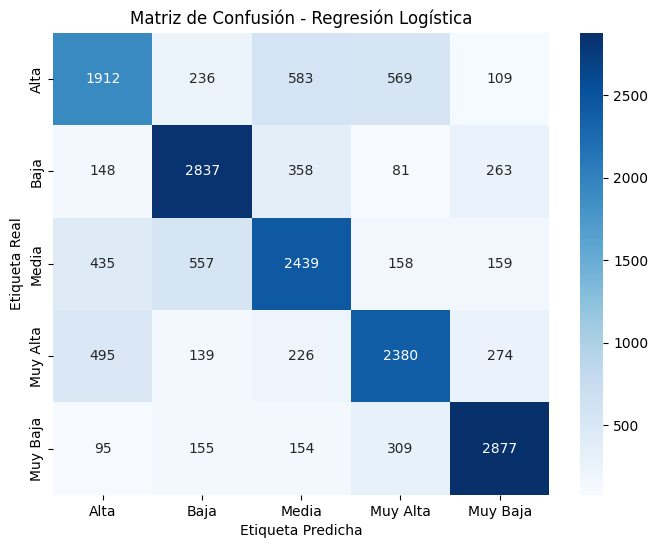

In [652]:

# Generar predicciones con tu modelo de regresión logística
y_pred_lr = modelo_lr_random.predict(X_test)

# Calcular la matriz
cm = confusion_matrix(y_test, y_pred_lr, labels=modelo_lr_random.classes_)

# Visualización
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=modelo_lr_random.classes_,
            yticklabels=modelo_lr_random.classes_)

plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Real')
plt.show()

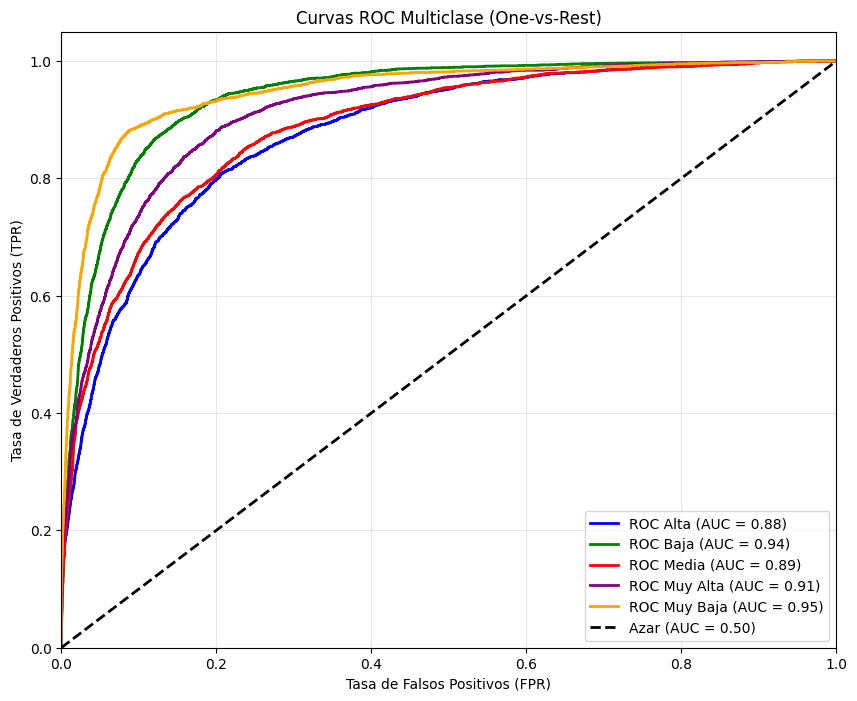


Reporte de Clasificación Final:

              precision    recall  f1-score   support

        Alta       0.62      0.56      0.59      3409
        Baja       0.72      0.77      0.75      3687
       Media       0.65      0.65      0.65      3748
    Muy Alta       0.68      0.68      0.68      3514
    Muy Baja       0.78      0.80      0.79      3590

    accuracy                           0.69     17948
   macro avg       0.69      0.69      0.69     17948
weighted avg       0.69      0.69      0.69     17948



In [653]:

clases = modelo_lr_random.classes_

# 1. Binarizar etiquetas para el análisis One-vs-Rest
y_test_bin = label_binarize(y_test, classes=clases)
n_clases = y_test_bin.shape[1]

# 2. Obtener probabilidades predictivas
y_score = modelo_lr_random.predict_proba(X_test)

# 3. Configurar gráfico
plt.figure(figsize=(10, 8))
colores = ['blue', 'green', 'red', 'purple', 'orange']

# 4. Calcular y dibujar curva para cada clase
for i, color in zip(range(n_clases), colores):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'ROC {clases[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Azar (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curvas ROC Multiclase (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# Imprimir el reporte de clasificación como respaldo numérico
print("\nReporte de Clasificación Final:\n")
print(classification_report(y_test, y_pred_lr))

In [654]:

# 1. Comprobar la identidad de los modelos
print("--- 1. IDENTIDAD DEL ALGORITMO ---")
print("Modelo 1:", type(modelo_lr_random.named_steps['modelo']))
print("Modelo 2:", type(best_tree.named_steps['modelo']))

# 2. Comparar en qué canciones se equivocan o aciertan
y_pred_lr = modelo_lr_random.predict(X_test)
y_pred_dtc = best_tree.predict(X_test)

diferencias_pred = np.sum(y_pred_lr != y_pred_dtc)
total_casos = len(y_test)

print("\n--- 2. PREDICCIONES EXACTAS ---")
print(f"De {total_casos} canciones de prueba, los modelos toman decisiones DISTINTAS en {diferencias_pred} canciones.")

# 3. La prueba definitiva: Probabilidades matemáticas
y_proba_lr = modelo_lr_random.predict_proba(X_test)
y_proba_dtc = best_tree.predict_proba(X_test)

diferencia_proba = np.sum(np.abs(y_proba_lr - y_proba_dtc))
print("\n--- 3. PROBABILIDADES MATEMÁTICAS ---")
print(f"Diferencia acumulada en el cálculo de probabilidad: {diferencia_proba:.2f}")

--- 1. IDENTIDAD DEL ALGORITMO ---
Modelo 1: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Modelo 2: <class 'sklearn.tree._classes.DecisionTreeClassifier'>

--- 2. PREDICCIONES EXACTAS ---
De 17948 canciones de prueba, los modelos toman decisiones DISTINTAS en 2956 canciones.

--- 3. PROBABILIDADES MATEMÁTICAS ---
Diferencia acumulada en el cálculo de probabilidad: 5597.83


# Modelos de Regresión

## Regresión (Lineal)

In [655]:
X = df[['speechiness', 'time_signature', 'valence', 'loudness', 'instrumentalness', 'es_colaboracion', 'track_genre', 'artista_principal']]
y_numerico = df['popularity']

X_train, X_test, y_train, y_test = train_test_split(X, y_numerico, test_size=0.2, random_state=42)

In [656]:
# pipeline para modelo de regresión lineal base
pipeline_rl = Pipeline(steps=[
    ("preprocesamiento", pipeline_regresion),
    ("modelo", LinearRegression())
])

In [657]:
metricas_rl = evaluar_modelo_regresion(pipeline_rl, X_train, X_test, y_train, y_test)
print(f"{'R2':<20}: {np.sqrt(metricas_rl['r2_score']):.4f}")
print(f"{'MAE':<20}: {metricas_rl['mean_absolute_error']:.4f}")

R2                  : 0.7319
MAE                 : 9.1790


In [658]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_rl.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_rl.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.67078
Score del modelo en test                :0.53564


## Regresión (Random Forest)

In [659]:
# pipeline para modelo de regresión Random Forest
pipeline_rf = Pipeline(steps=[
    ("preprocesamiento", pipeline_regresion),
    ("modelo", RandomForestRegressor(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=15,
        min_samples_split=30,
        n_jobs=-1,
        random_state=42
    ))
])

In [660]:
metricas_rf = evaluar_modelo_regresion(pipeline_rf, X_train, X_test, y_train, y_test)
print(f"{'R2':<20}: {np.sqrt(metricas_rf['r2_score']):.4f}")
print(f"{'MAE':<20}: {metricas_rf['mean_absolute_error']:.4f}")

R2                  : 0.7511
MAE                 : 8.6158


In [661]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_rf.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_rf.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.69496
Score del modelo en test                :0.56421


## Regresión (Árbol de decisión)

In [662]:
# pipeline para modelo de regresión árbol de decisión
pipeline_tree = Pipeline(steps=[
    ("preprocesamiento", pipeline_regresion),
    ("modelo", DecisionTreeRegressor(random_state=42))
])

In [663]:
metricas_tree = evaluar_modelo_regresion(pipeline_tree, X_train, X_test, y_train, y_test)
print(f"{'R2':<20}: {np.sqrt(metricas_tree['r2_score']):.4f}")
print(f"{'MAE':<20}: {metricas_tree['mean_absolute_error']:.4f}")

R2                  : 0.4099
MAE                 : 11.6472


In [664]:
print(f"{'Score del modelo en entrenamiento':<40}:{pipeline_tree.score(X_train, y_train):.5f}")
print(f"{'Score del modelo en test': <40}:{pipeline_tree.score(X_test, y_test):.5f}")

Score del modelo en entrenamiento       :0.44053
Score del modelo en test                :0.16803


## Gráficos de Regresión

In [665]:
# ==============================================================================
# 1. ENTRENAMIENTO Y OBTENCIÓN DE PREDICCIONES
# ==============================================================================
# Aseguramos el ajuste del pipeline y generamos los vectores de predicción
pipeline_rf.fit(X_train, y_train)

y_pred_train = pipeline_rf.predict(X_train)
y_pred_test = pipeline_rf.predict(X_test)

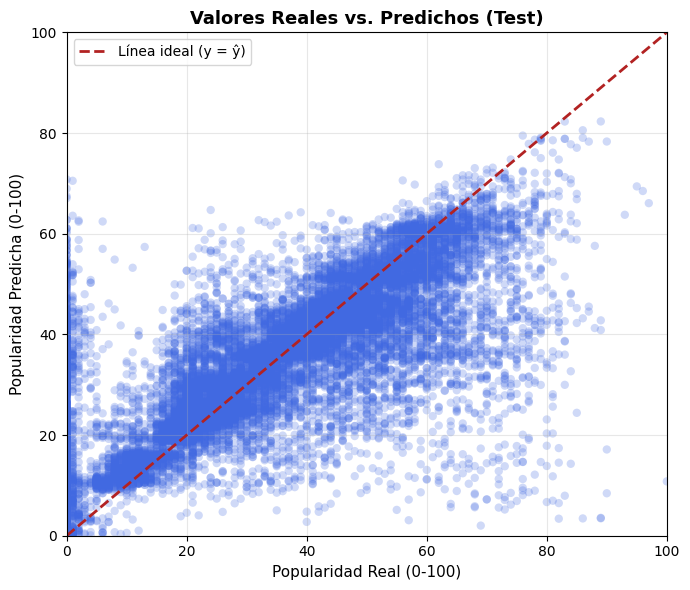

In [666]:
# ==============================================================================
# 2. Gráfico: Valores Reales vs. Predichos
# ==============================================================================

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_test, alpha=0.25, color="royalblue", edgecolor="none")
plt.plot([0, 100], [0, 100], color="firebrick", linestyle="--", linewidth=2, label="Línea ideal (y = ŷ)")

plt.title("Valores Reales vs. Predichos (Test)", fontsize=13, fontweight="bold")
plt.xlabel("Popularidad Real (0-100)", fontsize=11)
plt.ylabel("Popularidad Predicha (0-100)", fontsize=11)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

In [667]:
# ==============================================================================
# 3. TABLA COMPARATIVA CONSOLIDADA (TRAIN VS. TEST)
# ==============================================================================

tabla_metricas = pd.DataFrame({
    "Conjunto": ["Entrenamiento (Train)", "Prueba (Test)"],
    "R²": [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
    "MAE": [mean_absolute_error(y_train, y_pred_train), mean_absolute_error(y_test, y_pred_test)]
})

print("="*60)
print("RESUMEN DE RENDIMIENTO DEL MODELO FINAL (RANDOM FOREST)")
print("="*60)
print(tabla_metricas.to_string(index=False))

RESUMEN DE RENDIMIENTO DEL MODELO FINAL (RANDOM FOREST)
             Conjunto       R²      MAE
Entrenamiento (Train) 0.694964 6.934585
        Prueba (Test) 0.564213 8.615774
